<a href="https://colab.research.google.com/github/hady1220/Video-Audio-Editor/blob/main/Video_Audio_Editor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#@title ⚙️ 0. تثبيت المكتبات وتجهيز البيئة المعزولة (uv + Python 3.11) وخط Cairo
import sys
import shutil
import subprocess
import urllib.request
from pathlib import Path

ENV_DIR = Path("/content/df_env")
DEEPFILTER_BIN = ENV_DIR / "bin" / "deepFilter"
ENV_PYTHON = ENV_DIR / "bin" / "python"
FONT_DIR = Path("/usr/local/share/fonts/cairo")
FONT_FILE = FONT_DIR / "Cairo-Bold.ttf"

VIDEO_EXTS = {".mp4", ".mkv", ".mov", ".avi", ".webm"}
AUDIO_EXTS = {".wav", ".mp3", ".m4a", ".flac", ".aac", ".ogg"}
output_folder = "/content/mastered_output"
Path(output_folder).mkdir(parents=True, exist_ok=True)
Path("/content/my_media").mkdir(parents=True, exist_ok=True)


def run_step(cmd: list[str], step_name: str) -> None:
    """تشغيل الأمر مع طباعة الخطأ الحقيقي بالكامل في حال الفشل."""
    res = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    if res.returncode != 0:
        print(f"❌ فشل في [{step_name}]:\n{res.stderr or res.stdout}")
        raise RuntimeError(f"Step failed: {step_name}")


# 1. إنشاء بيئة Python 3.11 معزولة عبر uv وتثبيت DeepFilterNet بدون أي تعارض
if not DEEPFILTER_BIN.exists():
    print("🔧 [1/3] جاري تثبيت uv وإنشاء بيئة Python 3.11 معزولة لـ DeepFilterNet...")
    if ENV_DIR.exists():
        shutil.rmtree(ENV_DIR)

    run_step([sys.executable, "-m", "pip", "install", "-q", "uv"], "تثبيت uv")
    run_step(["uv", "venv", str(ENV_DIR), "--python", "3.11", "--seed"], "إنشاء بيئة Python 3.11")

    print("📦 جاري تثبيت PyTorch 2.5.1 و DeepFilterNet داخل البيئة المعزولة...")
    run_step([
        "uv", "pip", "install", "--python", str(ENV_PYTHON),
        "torch==2.5.1", "torchaudio==2.5.1",
        "--index-url", "https://download.pytorch.org/whl/cpu"
    ], "تثبيت torch و torchaudio")

    run_step([
        "uv", "pip", "install", "--python", str(ENV_PYTHON),
        "deepfilternet", "soundfile"
    ], "تثبيت deepfilternet و soundfile")

print("✅ [1/3] بيئة DeepFilterNet (Python 3.11) جاهزة وتعمل بدون أي ترقيع.")

# 2. تثبيت faster-whisper في البيئة الرئيسية (يدعم T4 GPU)
print("🔧 [2/3] جاري التحقق من مكتبة faster-whisper...")
run_step([sys.executable, "-m", "pip", "install", "-q", "faster-whisper"], "تثبيت faster-whisper")
print("✅ [2/3] مكتبة faster-whisper جاهزة.")

# 3. تحميل وتثبيت خط Cairo Bold العربي مع رابط احتياطي تلقائي
FONT_DIR.mkdir(parents=True, exist_ok=True)
if FONT_FILE.exists() and FONT_FILE.stat().st_size == 0:
    FONT_FILE.unlink()

FONT_URLS = [
    "https://github.com/Gue3bara/Cairo/raw/master/fonts/ttf/Cairo-Bold.ttf",
    "https://github.com/google/fonts/raw/main/ofl/cairo/Cairo%5Bslnt%2Cwght%5D.ttf",
]

if not FONT_FILE.exists():
    print("🔤 [3/3] جاري تحميل وتثبيت خط Cairo Bold...")
    downloaded = False
    for url in FONT_URLS:
        try:
            urllib.request.urlretrieve(url, str(FONT_FILE))
            if FONT_FILE.stat().st_size > 10_000:
                downloaded = True
                break
        except Exception:
            continue

    if not downloaded:
        raise RuntimeError("❌ تعذر تحميل خط Cairo من جميع الروابط.")

    run_step(["fc-cache", "-f"], "تحديث كاش الخطوط")

print(f"✅ [3/3] خط Cairo Bold جاهز ({FONT_FILE.stat().st_size // 1024} KB). يمكنك الآن البدء بالخلية 1!")

🔧 [1/3] جاري تثبيت uv وإنشاء بيئة Python 3.11 معزولة لـ DeepFilterNet...
📦 جاري تثبيت PyTorch 2.5.1 و DeepFilterNet داخل البيئة المعزولة...
✅ [1/3] بيئة DeepFilterNet (Python 3.11) جاهزة وتعمل بدون أي ترقيع.
🔧 [2/3] جاري التحقق من مكتبة faster-whisper...
✅ [2/3] مكتبة faster-whisper جاهزة.
🔤 [3/3] جاري تحميل وتثبيت خط Cairo Bold...
✅ [3/3] خط Cairo Bold جاهز (585 KB). يمكنك الآن البدء بالخلية 1!


In [7]:
#@title 📤 1. رفع ملف فيديو أو صوت من الجهاز
import shutil
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files

UPLOAD_DIR = Path("/content/my_media")
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)

upload_btn = widgets.Button(
    description="رفع ملف من الجهاز",
    icon="upload",
    button_style="primary",
    layout=widgets.Layout(width="260px", height="42px")
)
upload_out = widgets.Output()

def on_upload_clicked(b):
    with upload_out:
        clear_output()
        print("📂 اختر الملف من جهازك...")
        uploaded = files.upload()
        if not uploaded:
            print("⚠️ لم يتم اختيار أي ملف.")
            return

        filename = list(uploaded.keys())[0]
        src_path = Path("/content") / filename
        dest_path = UPLOAD_DIR / filename
        shutil.move(str(src_path), str(dest_path))

        globals()["input_path"] = str(dest_path)
        print(f"✅ تم الرفع بنجاح!")
        print(f"📌 الملف الجاهز للمعالجة: {dest_path}")

upload_btn.on_click(on_upload_clicked)
display(upload_btn, upload_out)

Button(button_style='primary', description='رفع ملف من الجهاز', icon='upload', layout=Layout(height='42px', wi…

Output()

In [8]:
#@title 🎙️ 2. معالجة الصوت الإذاعي + قص الصمت (محصّنة ضد أخطاء الجلسة)
#@markdown ### 🎛️ إعدادات العزل والصوت الإذاعي
atten_lim_db = 100 #@param {type:"slider", min:6, max:100, step:2}
loudness_profile = "YouTube (-14 LUFS)" #@param ["YouTube (-14 LUFS)", "Reels / TikTok (-12 LUFS)", "Podcast (-16 LUFS)"]
warmth_boost_db = 3.0 #@param {type:"slider", min:0.0, max:4.5, step:0.5}
presence_boost_db = 3.0 #@param {type:"slider", min:0.0, max:4.5, step:0.5}

#@markdown ---
#@markdown ### ✂️ قص فترات الصمت الطويلة تلقائياً (اختياري)
trim_silence = True #@param {type:"boolean"}
min_silence_sec = 0.8 #@param {type:"slider", min:0.3, max:3.0, step:0.1}
silence_threshold_db = -35 #@param {type:"slider", min:-50, max:-20, step:1}
speech_padding_sec = 0.15 #@param {type:"slider", min:0.05, max:0.4, step:0.05}

import re
import json
import time
import shutil
import tempfile
import threading
import subprocess
from pathlib import Path
from tqdm.notebook import tqdm

# قيم افتراضية آمنة لضمان عدم حدوث NameError حتى لو أُعيد تشغيل الجلسة
DEEPFILTER_BIN = Path(globals().get("DEEPFILTER_BIN", "/content/df_env/bin/deepFilter"))
VIDEO_EXTS = globals().get("VIDEO_EXTS", {".mp4", ".mkv", ".mov", ".avi", ".webm"})
AUDIO_EXTS = globals().get("AUDIO_EXTS", {".wav", ".mp3", ".m4a", ".flac", ".aac", ".ogg"})
output_folder = globals().get("output_folder", "/content/mastered_output")
Path(output_folder).mkdir(parents=True, exist_ok=True)

LOUDNESS_MAP = {
    "YouTube (-14 LUFS)": -14,
    "Reels / TikTok (-12 LUFS)": -12,
    "Podcast (-16 LUFS)": -16,
}

def get_media_duration(file_path: Path) -> float:
    try:
        res = subprocess.run([
            "ffprobe", "-v", "error", "-show_entries", "format=duration",
            "-of", "default=noprint_wrappers=1:nokey=1", str(file_path)
        ], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, check=True)
        return max(float(res.stdout.strip()), 0.1)
    except Exception:
        return 0.0

def run_ffmpeg_progress(cmd: list[str], total_duration: float, desc: str) -> None:
    prog_cmd = [cmd[0], "-progress", "pipe:1", "-nostats"] + cmd[1:]
    process = subprocess.Popen(prog_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, bufsize=1)
    pbar = tqdm(
        total=round(total_duration, 1) if total_duration > 0 else None,
        desc=desc, unit="s",
        bar_format="{l_bar}{bar}| {n:.1f}/{total:.1f}s [{elapsed}<{remaining}]" if total_duration > 0 else "{desc}: {elapsed}s"
    )
    current_sec = 0.0
    for line in process.stdout:
        line = line.strip()
        if line.startswith("out_time_us="):
            val = line.split("=", 1)[1]
            if val.isdigit():
                new_sec = int(val) / 1_000_000.0
                delta = new_sec - current_sec
                if delta > 0:
                    pbar.update(min(delta, max(0, total_duration - current_sec)) if total_duration > 0 else delta)
                    current_sec = new_sec
        elif line == "progress=end" and total_duration > 0 and current_sec < total_duration:
            pbar.update(total_duration - current_sec)
    _, stderr_data = process.communicate()
    pbar.close()
    if process.returncode != 0:
        raise RuntimeError(f"❌ فشل في مرحلة [{desc}]:\n{stderr_data}")

def run_deepfilter_progress(cmd: list[str], desc: str) -> None:
    process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    stop_flag = False
    def ticker():
        with tqdm(desc=desc, bar_format="{desc} ⏳ {elapsed} ...") as pbar:
            while not stop_flag:
                time.sleep(0.5)
                pbar.refresh()
    t = threading.Thread(target=ticker, daemon=True)
    t.start()
    _, stderr_data = process.communicate()
    stop_flag = True
    t.join()
    if process.returncode != 0:
        raise RuntimeError(f"❌ فشل في مرحلة [{desc}]:\n{stderr_data}")

def build_pre_loudnorm_af() -> str:
    return (
        f"highpass=f=85:p=2,"
        f"agate=threshold=-42dB:ratio=3:attack=15:release=150,"
        f"equalizer=f=190:t=q:w=1.2:g={warmth_boost_db},"
        f"equalizer=f=450:t=q:w=2.0:g=-3.0,"
        f"equalizer=f=4200:t=q:w=1.5:g={presence_boost_db},"
        f"acompressor=threshold=-18dB:ratio=3.5:attack=10:release=100:makeup=4dB,"
        f"alimiter=limit=-1.5dB:attack=5:release=60"
    )

def trim_silence_from_media(input_media: Path, output_media: Path, is_video: bool, tmp_dir: Path) -> bool:
    duration = get_media_duration(input_media)
    res = subprocess.run([
        "ffmpeg", "-hide_banner", "-i", str(input_media),
        "-af", f"silencedetect=noise={silence_threshold_db}dB:d={min_silence_sec}",
        "-f", "null", "-"
    ], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

    starts = [float(x) for x in re.findall(r"silence_start:\s*([0-9.]+)", res.stderr)]
    ends = [float(x) for x in re.findall(r"silence_end:\s*([0-9.]+)", res.stderr)]
    if not starts:
        print("ℹ️ لم يتم العثور على فترات صمت طويلة تستدعي القص.")
        return False
    if len(ends) < len(starts):
        ends.append(duration)

    keep_segments, cursor = [], 0.0
    for s_start, s_end in zip(starts, ends):
        seg_start = max(0.0, cursor - speech_padding_sec) if cursor > 0 else 0.0
        seg_end = min(duration, s_start + speech_padding_sec)
        if seg_end - seg_start > 0.05:
            keep_segments.append([seg_start, seg_end])
        cursor = s_end
    if cursor < duration:
        seg_start = max(0.0, cursor - speech_padding_sec)
        if duration - seg_start > 0.05:
            keep_segments.append([seg_start, duration])

    merged = []
    for seg in keep_segments:
        if not merged or seg[0] > merged[-1][1]:
            merged.append(seg)
        else:
            merged[-1][1] = max(merged[-1][1], seg[1])
    if not merged:
        return False

    filter_lines, concat_inputs = [], []
    for idx, (s, e) in enumerate(merged):
        if is_video:
            filter_lines.append(f"[0:v]trim=start={s:.3f}:end={e:.3f},setpts=PTS-STARTPTS[v{idx}];")
            filter_lines.append(f"[0:a]atrim=start={s:.3f}:end={e:.3f},asetpts=PTS-STARTPTS[a{idx}];")
            concat_inputs.append(f"[v{idx}][a{idx}]")
        else:
            filter_lines.append(f"[0:a]atrim=start={s:.3f}:end={e:.3f},asetpts=PTS-STARTPTS[a{idx}];")
            concat_inputs.append(f"[a{idx}]")

    n = len(merged)
    filter_lines.append(
        f"{''.join(concat_inputs)}concat=n={n}:v={1 if is_video else 0}:a=1{'[outv][outa]' if is_video else '[outa]'}"
    )
    script_file = tmp_dir / "trim_filter.txt"
    script_file.write_text("\n".join(filter_lines), encoding="utf-8")

    expected_dur = sum(e - s for s, e in merged)
    if is_video:
        cmd = [
            "ffmpeg", "-y", "-i", str(input_media), "-filter_complex_script", str(script_file),
            "-map", "[outv]", "-map", "[outa]", "-c:v", "libx264", "-preset", "fast", "-crf", "18",
            "-c:a", "aac", "-b:a", "320k", "-ar", "48000", "-movflags", "+faststart", str(output_media)
        ]
    else:
        cmd = [
            "ffmpeg", "-y", "-i", str(input_media), "-filter_complex_script", str(script_file),
            "-map", "[outa]", "-ar", "48000", "-c:a", "pcm_s16le", str(output_media)
        ]

    run_ffmpeg_progress(cmd, expected_dur, "[6/6] ✂️ قص الصمت وإعادة التزامن")
    saved_sec = max(0.0, duration - get_media_duration(output_media))
    print(f"✂️ تم قص {saved_sec:.1f} ثانية من الصمت ({len(starts)} وقفة).")
    return True

# --- التنفيذ الرئيسي مع التحقق المسبق ---
if not DEEPFILTER_BIN.exists():
    print("❌ بيئة DeepFilterNet غير مثبتة في هذه الجلسة. يرجى تشغيل (الخلية 0) أولاً ثم إعادة تشغيل هذه الخلية.")
elif "input_path" not in globals() or not Path(input_path).exists():
    print("❌ يرجى رفع ملف أولاً باستخدام (الخلية 1).")
else:
    file_path = Path(input_path)
    out_dir = Path(output_folder)
    out_dir.mkdir(parents=True, exist_ok=True)
    ext = file_path.suffix.lower()
    is_video = ext in VIDEO_EXTS
    out_ext = ext if is_video else ".wav"
    final_output = out_dir / f"{file_path.stem}_mastered{out_ext}"

    total_sec = get_media_duration(file_path)
    target_lufs, target_tp, target_lra = LOUDNESS_MAP[loudness_profile], -1.5, 7
    pre_af = build_pre_loudnorm_af()

    with tempfile.TemporaryDirectory(prefix="df_master_") as tmp:
        tmp_dir = Path(tmp)
        raw_wav = tmp_dir / "01_raw_48k.wav"
        df_out_dir = tmp_dir / "02_df_clean"
        df_out_dir.mkdir()
        mastered_wav = tmp_dir / "03_master.wav"

        run_ffmpeg_progress([
            "ffmpeg", "-y", "-i", str(file_path), "-vn", "-ac", "1", "-ar", "48000", "-c:a", "pcm_s16le", str(raw_wav)
        ], total_sec, "[1/5] استخراج الصوت")

        df_cmd = [str(DEEPFILTER_BIN), str(raw_wav), "-o", str(df_out_dir)]
        if atten_lim_db < 100:
            df_cmd.extend(["--atten-lim-db", str(atten_lim_db)])
        run_deepfilter_progress(df_cmd, f"[2/5] 🧠 عزل الضوضاء AI ({atten_lim_db} dB)")
        clean_wav = list(df_out_dir.glob("*.wav"))[0]

        print("[3/5] 📏 المرور الأول (Pass 1): قياس مستويات الصوت...")
        p1_res = subprocess.run([
            "ffmpeg", "-hide_banner", "-i", str(clean_wav),
            "-af", f"{pre_af},loudnorm=I={target_lufs}:TP={target_tp}:LRA={target_lra}:print_format=json",
            "-f", "null", "-"
        ], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
        stats = json.loads(re.search(r"\{\s*\"input_i\".*?\}", p1_res.stderr, re.DOTALL).group(0))

        pass2_af = (
            f"{pre_af},loudnorm=I={target_lufs}:TP={target_tp}:LRA={target_lra}:"
            f"measured_I={stats['input_i']}:measured_TP={stats['input_tp']}:"
            f"measured_LRA={stats['input_lra']}:measured_thresh={stats['input_thresh']}:"
            f"offset={stats['target_offset']}:linear=true"
        )
        run_ffmpeg_progress([
            "ffmpeg", "-y", "-i", str(clean_wav), "-af", pass2_af, "-ar", "48000", "-c:a", "pcm_s16le", str(mastered_wav)
        ], total_sec, f"[4/5] 🎙️ معالجة البرودكاست ({loudness_profile})")

        if is_video:
            run_ffmpeg_progress([
                "ffmpeg", "-y", "-i", str(file_path), "-i", str(mastered_wav),
                "-c:v", "copy", "-map", "0:v:0", "-map", "1:a:0",
                "-c:a", "aac", "-b:a", "320k", "-ar", "48000", "-movflags", "+faststart", str(final_output)
            ], total_sec, "[5/5] 🎬 دمج الصوت مع الفيديو")
        else:
            shutil.copy2(mastered_wav, final_output)

        if trim_silence:
            trimmed_output = out_dir / f"{file_path.stem}_mastered_trimmed{out_ext}"
            if trim_silence_from_media(final_output, trimmed_output, is_video, tmp_dir):
                final_output = trimmed_output

    print(f"\n✅ اكتملت المعالجة بنجاح: {final_output}")

[1/5] استخراج الصوت:   0%|          | 0.0/166.2s [00:00<?]

[2/5] 🧠 عزل الضوضاء AI (100 dB) ⏳ 00:00 ...

[3/5] 📏 المرور الأول (Pass 1): قياس مستويات الصوت...


[4/5] 🎙️ معالجة البرودكاست (YouTube (-14 LUFS)):   0%|          | 0.0/166.2s [00:00<?]

[5/5] 🎬 دمج الصوت مع الفيديو:   0%|          | 0.0/166.2s [00:00<?]

ℹ️ لم يتم العثور على فترات صمت طويلة تستدعي القص.

✅ اكتملت المعالجة بنجاح: /content/mastered_output/Liquidity Sweep_c_mastered.mp4


In [9]:
#@title 🎧 3. مقارنة صوتية فورية (الأصلي مقابل المعالج)
start_sec = 0 #@param {type:"number"}
duration_sec = 20 #@param {type:"number"}

import subprocess
from pathlib import Path
from IPython.display import Audio, display, HTML

orig_path = Path(input_path)
out_ext = orig_path.suffix.lower() if orig_path.suffix.lower() in VIDEO_EXTS else ".wav"
mastered_path = Path(output_folder) / f"{orig_path.stem}_mastered{out_ext}"

if not orig_path.exists() or not mastered_path.exists():
    print("❌ تأكد من تشغيل الخلية 2 بنجاح أولاً.")
else:
    orig_clip, master_clip = "/content/_compare_orig.wav", "/content/_compare_master.wav"
    for src, dst in [(orig_path, orig_clip), (mastered_path, master_clip)]:
        subprocess.run([
            "ffmpeg", "-y", "-ss", str(start_sec), "-t", str(duration_sec),
            "-i", str(src), "-vn", "-ac", "1", "-ar", "48000", dst
        ], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)

    display(HTML(f"<h4>🔴 الصوت الأصلي (من الثانية {start_sec} لمدة {duration_sec} ثانية):</h4>"))
    display(Audio(orig_clip))
    display(HTML(f"<h4>🟢 الصوت المعالج (DeepFilterNet + Broadcast EQ):</h4>"))
    display(Audio(master_clip))

/tmp/ipykernel_4570/1047970382.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


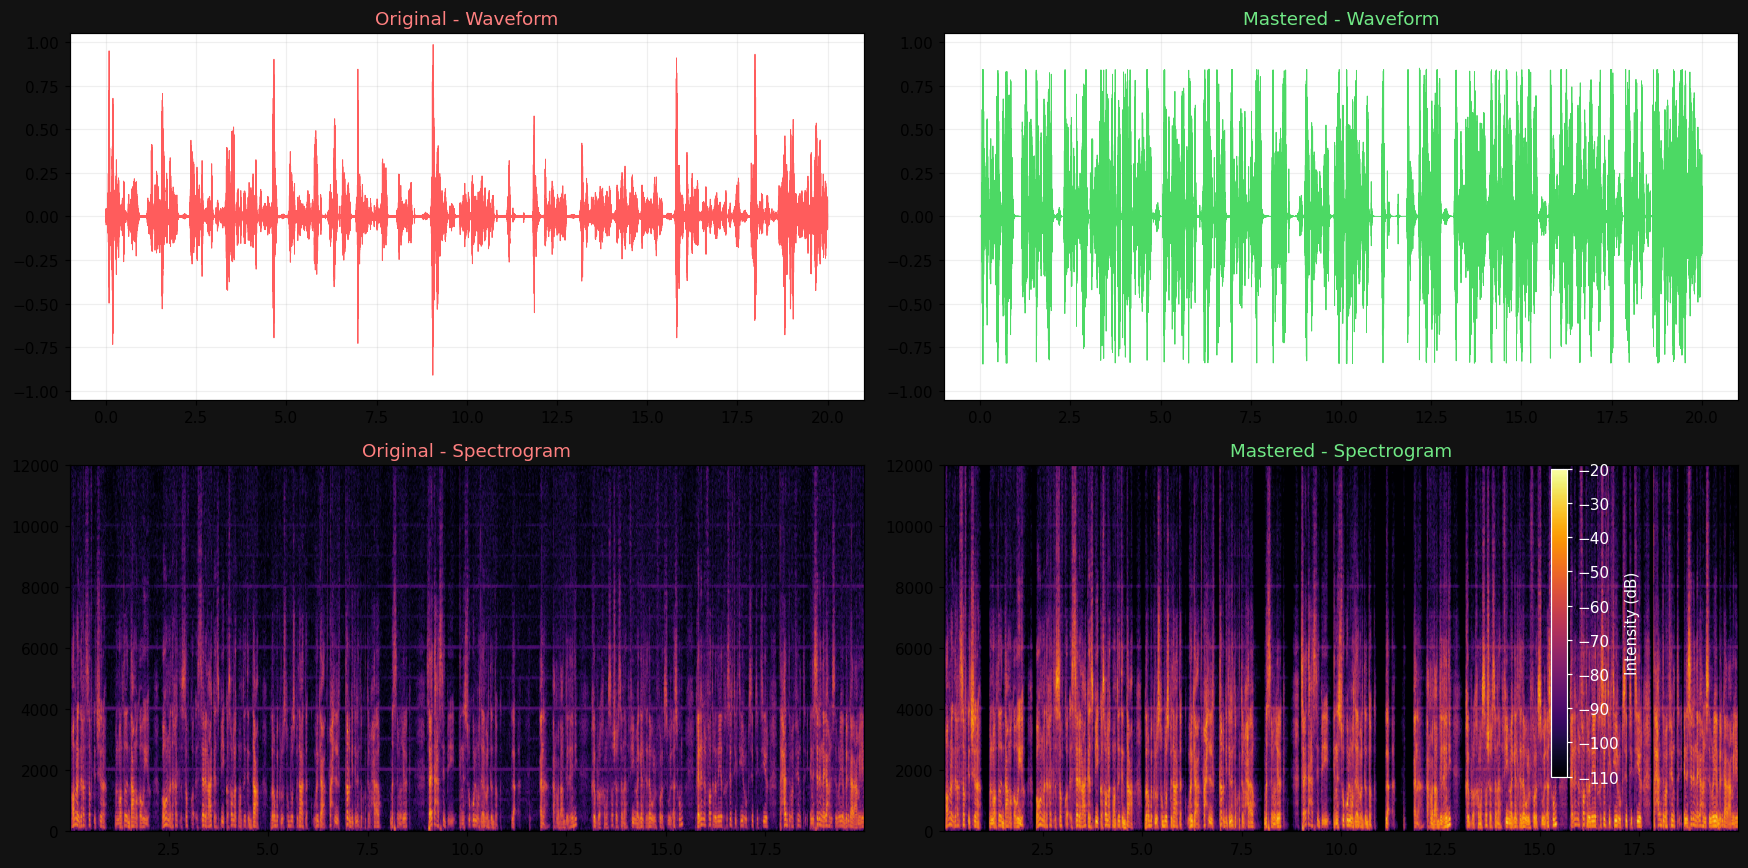

In [10]:
#@title 📊 4. مقارنة بصرية (Waveform & Spectrogram)
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

orig_clip, master_clip = "/content/_compare_orig.wav", "/content/_compare_master.wav"
if not os.path.exists(orig_clip) or not os.path.exists(master_clip):
    print("❌ يرجى تشغيل الخلية 3 أولاً لتوليد مقطعي المقارنة.")
else:
    sr_orig, y_orig = wavfile.read(orig_clip)
    sr_mast, y_mast = wavfile.read(master_clip)
    y_orig, y_mast = y_orig.astype(np.float32) / 32768.0, y_mast.astype(np.float32) / 32768.0
    t_orig = np.linspace(0, len(y_orig) / sr_orig, num=len(y_orig))
    t_mast = np.linspace(0, len(y_mast) / sr_mast, num=len(y_mast))

    fig, axes = plt.subplots(2, 2, figsize=(16, 8), dpi=110)
    plt.style.use("dark_background")
    fig.patch.set_facecolor("#121212")

    axes[0, 0].plot(t_orig, y_orig, color="#ff5c5c", linewidth=0.6)
    axes[0, 0].set_title("Original - Waveform", color="#ff8080")
    axes[0, 0].set_ylim(-1.05, 1.05)
    axes[0, 0].grid(alpha=0.2)

    axes[0, 1].plot(t_mast, y_mast, color="#4cd964", linewidth=0.6)
    axes[0, 1].set_title("Mastered - Waveform", color="#70e885")
    axes[0, 1].set_ylim(-1.05, 1.05)
    axes[0, 1].grid(alpha=0.2)

    axes[1, 0].specgram(y_orig, NFFT=1024, Fs=sr_orig, noverlap=512, cmap="inferno", vmin=-110, vmax=-20)
    axes[1, 0].set_title("Original - Spectrogram", color="#ff8080")
    axes[1, 0].set_ylim(0, 12000)

    _, _, _, im2 = axes[1, 1].specgram(y_mast, NFFT=1024, Fs=sr_mast, noverlap=512, cmap="inferno", vmin=-110, vmax=-20)
    axes[1, 1].set_title("Mastered - Spectrogram", color="#70e885")
    axes[1, 1].set_ylim(0, 12000)

    fig.colorbar(im2, ax=axes[1, :], orientation="vertical", fraction=0.02, pad=0.02, label="Intensity (dB)")
    plt.tight_layout()
    plt.show()

In [11]:
#@title 📏 5. تقرير قياس الصوت الرقمي (LUFS & True Peak QC Report)
import re
import json
import subprocess
from pathlib import Path

def measure_loudness(fp: Path) -> dict:
    res = subprocess.run([
        "ffmpeg", "-hide_banner", "-i", str(fp),
        "-af", "loudnorm=I=-14:TP=-1.5:LRA=7:print_format=json", "-f", "null", "-"
    ], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    data = json.loads(re.search(r"\{\s*\"input_i\".*?\}", res.stderr, re.DOTALL).group(0))
    return {"lufs": float(data["input_i"]), "tp": float(data["input_tp"]), "lra": float(data["input_lra"])}

orig_path = Path(input_path)
out_ext = orig_path.suffix.lower() if orig_path.suffix.lower() in VIDEO_EXTS else ".wav"
mastered_path = Path(output_folder) / f"{orig_path.stem}_mastered{out_ext}"

if not orig_path.exists() or not mastered_path.exists():
    print("❌ تأكد من تشغيل الخلية 2 بنجاح أولاً.")
else:
    o, m = measure_loudness(orig_path), measure_loudness(mastered_path)
    print("=" * 68)
    print(f"{'المعيار الصوتي (Metric)':<28} | {'الأصلي (Orig)':>15} | {'المعالج (Master)':>16}")
    print("-" * 68)
    print(f"{'Integrated Loudness (LUFS)':<28} | {o['lufs']:>12.2f} LUFS | {m['lufs']:>11.2f} LUFS")
    print(f"{'True Peak (dBTP)':<28} | {o['tp']:>12.2f} dBTP | {m['tp']:>11.2f} dBTP")
    print(f"{'Loudness Range (LRA)':<28} | {o['lra']:>14.2f} LU | {m['lra']:>13.2f} LU")
    print("=" * 68)

المعيار الصوتي (Metric)      |   الأصلي (Orig) | المعالج (Master)
--------------------------------------------------------------------
Integrated Loudness (LUFS)   |       -22.04 LUFS |      -15.66 LUFS
True Peak (dBTP)             |        -0.11 dBTP |       -1.37 dBTP
Loudness Range (LRA)         |           3.20 LU |          2.60 LU


In [12]:
#@title ⏩ 5.5. التحكم في سرعة الفيديو والصوت (تسريع / تبطيء بنسبة 1%)
#@markdown حرك الشريط **يميناً** للتسريع (أكبر من 100%) أو **يساراً** للتبطيء (أقل من 100%) — القيمة `100` تعني السرعة الأصلية بدون تغيير:
speed_percent = 86 #@param {type:"slider", min:50, max:200, step:1}

import subprocess
from pathlib import Path

def build_atempo_chain(factor: float) -> str:
    """بناء سلسلة فلاتر atempo للحفاظ على نبرة الصوت الطبيعية مهما كانت السرعة."""
    filters = []
    remaining = factor
    while remaining > 2.0:
        filters.append("atempo=2.0")
        remaining /= 2.0
    while remaining < 0.5:
        filters.append("atempo=0.5")
        remaining /= 0.5
    filters.append(f"atempo={remaining:.4f}")
    return ",".join(filters)

if "input_path" not in globals() or not Path(input_path).exists():
    print("❌ يرجى رفع الملف وتشغيل الخلية 2 أولاً.")
else:
    orig_path = Path(input_path)
    out_dir = Path(output_folder)
    ext = orig_path.suffix.lower()
    is_video = ext in VIDEO_EXTS
    out_ext = ext if is_video else ".wav"

    # اختيار المصدر الأساسي المعالج (بدون تراكم سرعات سابقة)
    trimmed_vid = out_dir / f"{orig_path.stem}_mastered_trimmed{out_ext}"
    mastered_vid = out_dir / f"{orig_path.stem}_mastered{out_ext}"
    base_media = trimmed_vid if trimmed_vid.exists() else mastered_vid
    speed_output = out_dir / f"{base_media.stem}_speed{out_ext}"

    if not base_media.exists():
        print("❌ لم يتم العثور على الملف المعالج. شغّل الخلية 2 أولاً.")
    elif speed_percent == 100:
        if speed_output.exists():
            speed_output.unlink()
        print("ℹ️ السرعة مضبوطة على 100% (السرعة الأصلية) — سيتم استخدام الملف المعالج كما هو.")
    else:
        factor = speed_percent / 100.0
        diff = speed_percent - 100
        mode_txt = f"تسريع +{diff}%" if diff > 0 else f"تبطيء {diff}%"
        orig_dur = get_media_duration(base_media)
        new_dur = orig_dur / factor
        atempo_str = build_atempo_chain(factor)

        print(f"⚙️ جاري تطبيق [{mode_txt}] (المعامل: {factor:.2f}x)...")
        print(f"⏱️ المدة الأصلية: {orig_dur:.1f}s ➔ المدة الجديدة المتوقعة: {new_dur:.1f}s")

        if is_video:
            cmd = [
                "ffmpeg", "-y", "-i", str(base_media),
                "-vf", f"setpts=PTS/{factor:.4f}",
                "-af", atempo_str,
                "-c:v", "libx264", "-preset", "fast", "-crf", "18",
                "-c:a", "aac", "-b:a", "320k", "-ar", "48000",
                "-movflags", "+faststart", str(speed_output)
            ]
        else:
            cmd = [
                "ffmpeg", "-y", "-i", str(base_media),
                "-af", atempo_str,
                "-ar", "48000", "-c:a", "pcm_s16le", str(speed_output)
            ]

        run_ffmpeg_progress(cmd, new_dur, f"⏩ ضبط السرعة ({speed_percent}%)")
        print(f"✅ تم حفظ النسخة معدّلة السرعة بنجاح: {speed_output}")

⚙️ جاري تطبيق [تبطيء -14%] (المعامل: 0.86x)...
⏱️ المدة الأصلية: 166.2s ➔ المدة الجديدة المتوقعة: 193.3s


⏩ ضبط السرعة (86%):   0%|          | 0.0/193.3s [00:00<?]

✅ تم حفظ النسخة معدّلة السرعة بنجاح: /content/mastered_output/Liquidity Sweep_c_mastered_speed.mp4


In [15]:
#@title ✨ 6. توليد وحرق الترجمة الذكية (تلتقط السرعة الجديدة + RTL/LTR تلقائياً)
subtitle_mode = "ريلز ديناميكي (تلوين الكلمة لحظياً ASS)" #@param ["ملف SRT فقط بدون حرق", "يوتيوب (حرق SRT بحدود أو خلفية)", "ريلز ديناميكي (تلوين الكلمة لحظياً ASS)"]
whisper_model_size = "large-v3-turbo" #@param ["small", "medium", "large-v3-turbo", "large-v3"]
language_code = "auto" #@param ["auto", "ar", "en"]
words_per_line = 5 #@param {type:"slider", min:2, max:12, step:1}
highlight_color = "أصفر فاقع (Yellow)" #@param ["أصفر فاقع (Yellow)", "أخضر نيون (Neon Green)", "سماوي (Cyan)"]
font_size = 48 #@param {type:"slider", min:18, max:90, step:2}
margin_bottom = 90 #@param {type:"slider", min:20, max:260, step:10}
custom_terms = "Liquidity Sweep, False Breakout, Smart Money, Retail Traders, Order Block, Stop Loss" #@param {type:"string"}

import re
import json
import shutil
import torch
import subprocess
import numpy as np
from pathlib import Path
from scipy.io import wavfile
from tqdm.notebook import tqdm
from faster_whisper import WhisperModel

# قيم افتراضية آمنة لمنع NameError عند إعادة تشغيل الجلسة
VIDEO_EXTS = globals().get("VIDEO_EXTS", {".mp4", ".mkv", ".mov", ".avi", ".webm"})
output_folder = globals().get("output_folder", "/content/mastered_output")
Path(output_folder).mkdir(parents=True, exist_ok=True)

HIGHLIGHT_MAP = {
    "أصفر فاقع (Yellow)": "&H00FFFF&",
    "أخضر نيون (Neon Green)": "&H50FF00&",
    "سماوي (Cyan)": "&HFFFF00&",
}

def _get_dur(fp: Path) -> float:
    try:
        res = subprocess.run([
            "ffprobe", "-v", "error", "-show_entries", "format=duration",
            "-of", "default=noprint_wrappers=1:nokey=1", str(fp)
        ], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, check=True)
        return max(float(res.stdout.strip()), 0.1)
    except Exception:
        return 0.0

def _run_ff_prog(cmd: list[str], total_dur: float, desc: str) -> None:
    prog_cmd = [cmd[0], "-progress", "pipe:1", "-nostats"] + cmd[1:]
    proc = subprocess.Popen(prog_cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, bufsize=1)
    pbar = tqdm(
        total=round(total_dur, 1) if total_dur > 0 else None,
        desc=desc, unit="s",
        bar_format="{l_bar}{bar}| {n:.1f}/{total:.1f}s [{elapsed}<{remaining}]" if total_dur > 0 else "{desc}: {elapsed}s"
    )
    cur = 0.0
    for line in proc.stdout:
        line = line.strip()
        if line.startswith("out_time_us="):
            val = line.split("=", 1)[1]
            if val.isdigit():
                ns = int(val) / 1_000_000.0
                if ns > cur:
                    pbar.update(min(ns - cur, max(0, total_dur - cur)) if total_dur > 0 else (ns - cur))
                    cur = ns
        elif line == "progress=end" and total_dur > 0 and cur < total_dur:
            pbar.update(total_dur - cur)
    _, err = proc.communicate()
    pbar.close()
    if proc.returncode != 0:
        raise RuntimeError(f"❌ فشل في [{desc}]:\n{err}")

def fmt_srt(s: float) -> str:
    ms = int(round((s - int(s)) * 1000))
    t = int(s) + (1 if ms == 1000 else 0)
    ms = 0 if ms == 1000 else ms
    return f"{t//3600:02d}:{(t%3600)//60:02d}:{t%60:02d},{ms:03d}"

def fmt_ass(s: float) -> str:
    cs = int(round((s - int(s)) * 100))
    t = int(s) + (1 if cs == 100 else 0)
    cs = 0 if cs == 100 else cs
    return f"{t//3600}:{(t%3600)//60:02d}:{t%60:02d}.{cs:02d}"

def apply_bidi_direction(text: str, is_rtl: bool) -> str:
    """ضبط اتجاه النص بدقة (RTL للعربية مع حماية الكلمات الإنجليزية، أو LTR للإنجليزية)."""
    if not is_rtl:
        return f"\u202A\u200E{text}\u202C"
    protected = re.sub(
        r"([A-Za-z0-9][A-Za-z0-9\s\-\._/]*[A-Za-z0-9]|[A-Za-z0-9])",
        lambda m: f"\u202A{m.group(0)}\u202C",
        text
    )
    return f"\u202B\u200F{protected}\u202C"

def format_word_for_ass(word: str, is_rtl: bool) -> str:
    """حماية الكلمة الإنجليزية المنفردة داخل سطر عربي أثناء تلوين الكلمات."""
    w = word.strip()
    if is_rtl and re.fullmatch(r"[A-Za-z0-9\-\._/]+", w):
        return f"\u202A{w}\u202C"
    return w

if "input_path" not in globals() or not Path(input_path).exists():
    print("❌ يرجى رفع الملف في (الخلية 1) وتشغيل (الخلية 2) أولاً.")
else:
    orig_path = Path(input_path)
    out_dir = Path(output_folder)
    out_ext = orig_path.suffix.lower()

    # اختيار أحدث نسخة معالجة (معدّلة السرعة أولاً إن وُجدت، وإلا المقصوصة، وإلا المعالجة الأساسية)
    trimmed_vid = out_dir / f"{orig_path.stem}_mastered_trimmed{out_ext}"
    mastered_vid = out_dir / f"{orig_path.stem}_mastered{out_ext}"
    base_vid = trimmed_vid if trimmed_vid.exists() else mastered_vid
    speed_vid = out_dir / f"{base_vid.stem}_speed{out_ext}"
    target_video = speed_vid if speed_vid.exists() else base_vid

    if not target_video.exists():
        print("❌ لم يتم العثور على الفيديو المعالج. شغّل (الخلية 2) أولاً.")
    else:
        device = "cuda" if torch.cuda.is_available() else "cpu"
        compute_type = "float16" if device == "cuda" else "int8"
        print(f"🚀 تحميل Whisper ({whisper_model_size}) على [{device.upper()}]...")
        model = WhisperModel(whisper_model_size, device=device, compute_type=compute_type)

        # استخراج الصوت بـ FFmpeg إلى 16kHz لتجاوز أي تعارض مع PyAV
        tmp_16k = Path("/tmp/whisper_16k.wav")
        subprocess.run([
            "ffmpeg", "-y", "-i", str(target_video),
            "-vn", "-ac", "1", "-ar", "16000", "-c:a", "pcm_s16le", str(tmp_16k)
        ], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)

        _, wav_data = wavfile.read(str(tmp_16k))
        audio_np = wav_data.astype(np.float32) / 32768.0

        lang_arg = None if language_code == "auto" else language_code
        prompt_arg = custom_terms.strip() if custom_terms.strip() else None

        print(f"🎙️ جاري تفريغ الصوت وتوليد التوقيتات لـ: {target_video.name} ...")
        segments, info = model.transcribe(
            audio_np,
            language=lang_arg,
            initial_prompt=prompt_arg,
            beam_size=5,
            vad_filter=True,
            word_timestamps=True
        )
        segments = list(segments)

        detected_lang = lang_arg or info.language
        is_rtl = detected_lang in {"ar", "he", "fa", "ur"}
        dir_label = "يمين إلى يسار (RTL - عربي)" if is_rtl else f"يسار إلى يمين (LTR - {detected_lang})"
        print(f"🧭 اللغة المعتمدة: [{detected_lang}] — اتجاه الكتابة: {dir_label}")

        # 1. توليد ملف SRT مضبوط الاتجاه
        srt_lines, idx = [], 1
        for seg in segments:
            words = [w for w in (seg.words or []) if w.word.strip()]
            for i in range(0, len(words), words_per_line):
                ch = words[i : i + words_per_line]
                raw_txt = "".join(w.word for w in ch).strip()
                if raw_txt:
                    directed_txt = apply_bidi_direction(raw_txt, is_rtl)
                    srt_lines.append(f"{idx}\n{fmt_srt(ch[0].start)} --> {fmt_srt(ch[-1].end)}\n{directed_txt}\n")
                    idx += 1
        srt_path = target_video.with_suffix(".srt")
        srt_path.write_text("\n".join(srt_lines), encoding="utf-8")
        print(f"✅ تم توليد ملف SRT: {srt_path.name}")

        # 2. حرق الترجمة حسب النمط المختار
        if subtitle_mode != "ملف SRT فقط بدون حرق" and target_video.suffix.lower() in VIDEO_EXTS:
            dur = _get_dur(target_video)
            if "ريلز" in subtitle_mode:
                res = subprocess.run([
                    "ffprobe", "-v", "error", "-select_streams", "v:0",
                    "-show_entries", "stream=width,height", "-of", "json", str(target_video)
                ], stdout=subprocess.PIPE, text=True, check=True)
                st = json.loads(res.stdout)["streams"][0]
                vw, vh = int(st["width"]), int(st["height"])
                hl = HIGHLIGHT_MAP[highlight_color]
                encoding_code = 178 if is_rtl else 1

                header = f"""[Script Info]
ScriptType: v4.00+
PlayResX: {vw}
PlayResY: {vh}
WrapStyle: 0
ScaledBorderAndShadow: yes

[V4+ Styles]
Format: Name, Fontname, Fontsize, PrimaryColour, SecondaryColour, OutlineColour, BackColour, Bold, Italic, Underline, StrikeOut, ScaleX, ScaleY, Spacing, Angle, BorderStyle, Outline, Shadow, Alignment, MarginL, MarginR, MarginV, Encoding
Style: Reels,Cairo,{font_size},&H00FFFFFF,&H000000FF,&H00000000,&H80000000,-1,0,0,0,100,100,0,0,1,4,2,2,40,40,{margin_bottom},{encoding_code}

[Events]
Format: Layer, Start, End, Style, Name, MarginL, MarginR, MarginV, Effect, Text
"""
                d_lines = []
                prefix_dir = "\u202B\u200F" if is_rtl else "\u202A\u200E"
                for seg in segments:
                    words = [w for w in (seg.words or []) if w.word.strip()]
                    for i in range(0, len(words), words_per_line):
                        ch = words[i : i + words_per_line]
                        for a_idx, aw in enumerate(ch):
                            s_t = aw.start
                            e_t = ch[a_idx + 1].start if a_idx + 1 < len(ch) else aw.end
                            e_t = max(e_t, s_t + 0.05)
                            parts = []
                            for j, w in enumerate(ch):
                                clean_w = format_word_for_ass(w.word, is_rtl)
                                if j == a_idx:
                                    parts.append(f"{{\\c{hl}}}{clean_w}{{\\c&HFFFFFF&}}")
                                else:
                                    parts.append(clean_w)
                            line_body = f"{prefix_dir}{' '.join(parts)}\u202C"
                            d_lines.append(f"Dialogue: 0,{fmt_ass(s_t)},{fmt_ass(e_t)},Reels,,0,0,0,,{line_body}")

                ass_path = target_video.with_suffix(".ass")
                ass_path.write_text(header + "\n".join(d_lines), encoding="utf-8")
                shutil.copy2(ass_path, "/tmp/reels_subs.ass")
                out_vid = out_dir / f"{target_video.stem}_reels_subbed{out_ext}"
                vf_arg = "ass=/tmp/reels_subs.ass"
            else:
                shutil.copy2(srt_path, "/tmp/subs_burn.srt")
                out_vid = out_dir / f"{target_video.stem}_subbed{out_ext}"
                style = f"FontName=Cairo,FontSize={min(font_size, 32)},Bold=1,PrimaryColour=&H00FFFFFF,BorderStyle=3,Outline=6,BackColour=&H80000000,OutlineColour=&H80000000,Alignment=2,MarginV={margin_bottom}"
                vf_arg = f"subtitles=/tmp/subs_burn.srt:force_style='{style}'"

            _run_ff_prog([
                "ffmpeg", "-y", "-i", str(target_video), "-vf", vf_arg,
                "-c:v", "libx264", "-preset", "fast", "-crf", "18",
                "-c:a", "copy", "-movflags", "+faststart", str(out_vid)
            ], dur, "🎬 حرق الترجمة على الفيديو")
            print(f"🎉 تم إنتاج الفيديو المترجم بنجاح: {out_vid}")

🚀 تحميل Whisper (large-v3-turbo) على [CPU]...
🎙️ جاري تفريغ الصوت وتوليد التوقيتات لـ: Liquidity Sweep_c_mastered_speed.mp4 ...
🧭 اللغة المعتمدة: [ar] — اتجاه الكتابة: يمين إلى يسار (RTL - عربي)
✅ تم توليد ملف SRT: Liquidity Sweep_c_mastered_speed.srt


🎬 حرق الترجمة على الفيديو:   0%|          | 0.0/193.3s [00:00<?]

🎉 تم إنتاج الفيديو المترجم بنجاح: /content/mastered_output/Liquidity Sweep_c_mastered_speed_reels_subbed.mp4


In [16]:
#@title ⬇️ 7. تحميل الملف النهائي أو حزمة كاملة (ZIP) إلى الجهاز
import zipfile
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import files

out_dir = Path(globals().get("output_folder", "/content/mastered_output"))

if not out_dir.exists() or not any(out_dir.iterdir()):
    print("❌ مجلد المخرجات فارغ حالياً. شغّل الخلية 2 أولاً.")
else:
    all_files = sorted(
        [f for f in out_dir.iterdir() if f.is_file() and f.suffix.lower() != ".zip"],
        key=lambda f: f.stat().st_mtime, reverse=True
    )
    file_dropdown = widgets.Dropdown(
        options=[(f"{f.name} ({f.stat().st_size / (1024*1024):.1f} MB)", str(f)) for f in all_files],
        description="الملف:", layout=widgets.Layout(width="520px")
    )
    download_btn = widgets.Button(description="تحميل الملف المحدد فقط", icon="download", button_style="success", layout=widgets.Layout(width="250px", height="42px"))
    zip_download_btn = widgets.Button(description="تحميل الفيديو + الترجمة (ZIP)", icon="file-archive-o", button_style="info", layout=widgets.Layout(width="260px", height="42px"))
    download_out = widgets.Output()

    def on_download_clicked(b):
        with download_out:
            clear_output()
            sf = Path(file_dropdown.value)
            print(f"⬇️ جاري تحميل: {sf.name} ...")
            files.download(str(sf))

    def on_zip_download_clicked(b):
        with download_out:
            clear_output()
            sf = Path(file_dropdown.value)
            base = sf.stem
            for sfx in ("_reels_subbed", "_subbed"):
                if base.endswith(sfx):
                    base = base[:-len(sfx)]
                    break
            pack = [sf]
            for ext in (".srt", ".ass"):
                for cand in {sf.with_suffix(ext), out_dir / f"{base}{ext}"}:
                    if cand.exists() and cand not in pack:
                        pack.append(cand)
            zip_path = out_dir / f"{sf.stem}_package.zip"
            with zipfile.ZipFile(zip_path, "w") as zf:
                for f in pack:
                    zf.write(f, arcname=f.name, compress_type=zipfile.ZIP_DEFLATED if f.suffix.lower() in (".srt", ".ass") else zipfile.ZIP_STORED)
            print(f"📦 جاري تحميل الحزمة ({zip_path.stat().st_size / (1024*1024):.1f} MB): {zip_path.name} ...")
            files.download(str(zip_path))

    download_btn.on_click(on_download_clicked)
    zip_download_btn.on_click(on_zip_download_clicked)
    display(file_dropdown, widgets.HBox([download_btn, zip_download_btn]), download_out)

Dropdown(description='الملف:', layout=Layout(width='520px'), options=(('Liquidity Sweep_c_mastered_speed_reels…

Output()

In [ ]:
#@title 🧹 8. تنظيف المخرجات والملفات المؤقتة بأمان
import shutil
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display, clear_output

delete_raw_uploads = widgets.Checkbox(
    value=False,
    description="حذف الفيديوهات الخام المرفوعة في my_media أيضاً",
    indent=False
)
clean_btn = widgets.Button(
    description="تنظيف المساحة الآن",
    icon="trash",
    button_style="danger",
    layout=widgets.Layout(width="240px", height="40px")
)
clean_out = widgets.Output()

def _size_mb(p: Path) -> float:
    if not p.exists():
        return 0.0
    if p.is_file():
        return p.stat().st_size / (1024 * 1024)
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / (1024 * 1024)

def on_clean_clicked(b):
    with clean_out:
        clear_output()
        freed = 0.0
        out_dir = Path(globals().get("output_folder", "/content/mastered_output"))
        if out_dir.exists():
            freed += _size_mb(out_dir)
            shutil.rmtree(out_dir)
            out_dir.mkdir(parents=True, exist_ok=True)

        temp_files = [
            Path("/content/_compare_orig.wav"),
            Path("/content/_compare_master.wav"),
            Path("/tmp/subs_burn.srt"),
            Path("/tmp/reels_subs.ass"),
            Path("/tmp/whisper_16k.wav"),
        ]
        for tf in temp_files:
            if tf.exists():
                freed += _size_mb(tf)
                tf.unlink()

        if delete_raw_uploads.value:
            up_dir = Path("/content/my_media")
            if up_dir.exists():
                freed += _size_mb(up_dir)
                shutil.rmtree(up_dir)
                up_dir.mkdir(parents=True, exist_ok=True)

        print(f"✅ تم التنظيف بنجاح! المساحة المفرّغة: {freed:.1f} MB (البيئة والخطوط محفوظة وجاهزة).")

clean_btn.on_click(on_clean_clicked)
display(delete_raw_uploads, clean_btn, clean_out)

Checkbox(value=False, description='حذف الفيديوهات الخام المرفوعة في my_media أيضاً', indent=False)

Button(button_style='danger', description='تنظيف المساحة الآن', icon='trash', layout=Layout(height='40px', wid…

Output()